# 02 · Statistics problems in trading: estimation, stationarity and edge

**Original lecture:** [Quant Guild #3, *How to Make & Lose Money Trading*](https://github.com/romanmichaelpaolucci/Quant-Guild-Library/tree/main/2025%20Video%20Lectures/3.%20How%20to%20Make%20%26%20Lose%20Money%20Trading) · [video](https://youtu.be/WP9fb7AMFsI)

> **Starter notebook.** You write the code. Each task has an empty cell marked `# TODO`, followed by a **checkpoint** cell that prints ✅, ❌ with a hint, or ⏳ (not done yet). You can *Run All* at any time to see where you stand.
>
> The rules: **predict before you run**, **type it, don't paste it**, and if you're stuck for more than 15 minutes, ask Claude for a *hint*.

**The question.** A trader shows you 7 trades: 4 winners and 3 losers, positive average P/L. Do they have an edge? By the end you'll be able to answer with numbers, and you'll see why the honest answer is usually *we can't tell yet*.

| Part | Idea | Time |
|---|---|---|
| 1 | **Estimation:** how much can a sample of trades tell you? | Day 1–2 |
| 2 | **Stationarity:** what if the thing you estimate keeps moving? | Day 2 |
| 3 | **Edge:** the law of total expectation, breakeven win rates, equity curves | Day 3 |
| 4 | **Real data:** SPY's daily edge with a bootstrap confidence interval | Day 4 |
| 5 | **Your extension** + takeaways | Day 5 |

**Fill in when finished:** *What's new compared with the original* (one row per idea you added):

| New compared with the original | Where |
|---|---|
| *(e.g. bootstrap CI on a real edge)* | Part 4 |

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from qgs import load_prices, set_style
from qgs.checks import p02 as check

set_style()
rng = np.random.default_rng(42)

## Part 1 · Parameter estimation

Every trading statistic is an **estimate**: win rate, average win, Sharpe. Start with the simplest one. A coin lands heads with unknown probability $p$. After $n$ flips the natural estimate is

$$\hat p = \frac{\#\text{heads}}{n}, \qquad \mathbb E[\hat p] = p, \qquad \operatorname{sd}(\hat p) = \sqrt{\frac{p(1-p)}{n}}.$$

That last formula is the **standard error**. It shrinks like $1/\sqrt n$: to halve your uncertainty you need **four times** the data.

### Task 1.1
Write `estimate_p(n_flips, p, rng)`, which flips a coin with heads-probability `p` `n_flips` times and returns the fraction of heads.

*Useful:* `rng.random(n) < p` gives an array of True/False; `rng.binomial(n, p)` counts successes directly. Either works.

In [28]:
def estimate_p(n_flips, p, rng):
    p_est = rng.binomial(n_flips, p) / n_flips
    return p_est
    raise NotImplementedError

In [29]:
check.task1_1(estimate_p)

✅ Task 1.1 estimate_p: unbiased estimator of p


True

### Task 1.2
**Predict first** (write your guess here): with $n = 10$ flips of a fair coin, what is the standard deviation of $\hat p$? ➜ *my prediction: 0.158*

Now simulate 10,000 experiments of 10 flips each, store the estimates in `p_hats_10`, and plot a histogram. Mark the true $p = 0.5$ with a vertical line.

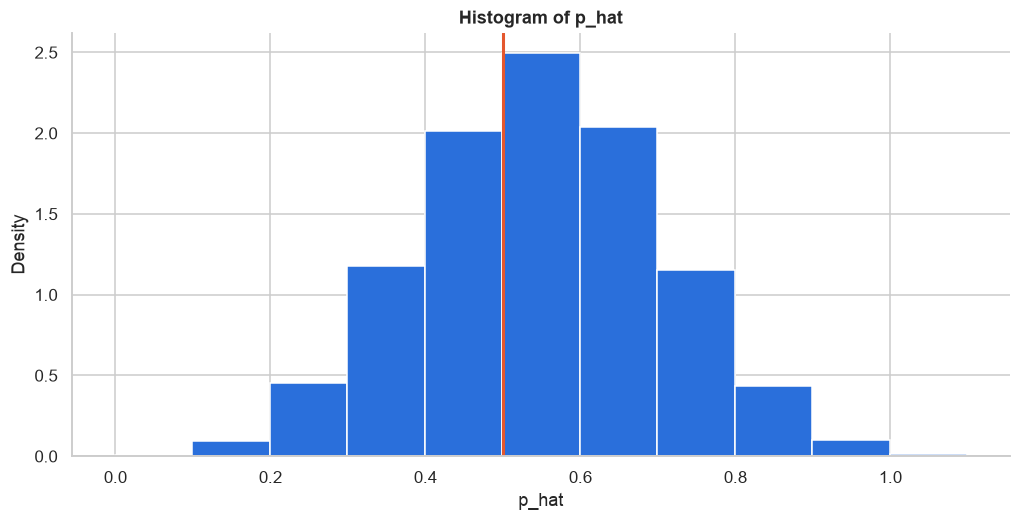

In [52]:
p_hats_10 = np.array([estimate_p(10, 0.5, rng) for run in range(10000)])
plt.hist(p_hats_10, bins=np.arange(-0.001, 1.10001, 0.1), density=True)
plt.axvline(0.5, color="C1", lw=2)
plt.xlabel("p_hat"); plt.ylabel("Density"); plt.title("Histogram of p_hat")
plt.show()

In [46]:
check.task1_2(p_hats_10)

✅ Task 1.2 sampling distribution: sd = 0.157 vs theory 0.158: 10 trades tell you almost nothing


True

### Task 1.3
How does the error shrink with more data? For each `n` in `ns`, simulate 2,000 estimates and store their standard deviation in `se_empirical` (an array with one value per `n`). Plot it against the theoretical $\sqrt{0.25/n}$ on **log-log** axes (`ax.loglog`). What slope do you see, and why?

Then answer with algebra: how many trades do you need for a 95% confidence interval of $\pm 2\%$ around a 50% win rate? Store it in `n_needed`.

In [8]:
ns = [10, 30, 100, 300, 1000, 3000]
se_empirical = None  # TODO

# TODO: log-log plot, empirical vs theory

n_needed = None  # TODO: solve 1.96 * sqrt(0.25 / n) = 0.02

In [9]:
check.task1_3(se_empirical, n_needed)

⏳ Task 1.3 standard error vs n: not done yet


False

✍️ **Interpret (2–3 sentences):** what does Task 1.3 imply for a trader who judges a new strategy after 30 trades?

*Your answer:*

## Part 2 · Stationarity

Part 1 assumed $p$ stays fixed. Markets don't do that. Now each experiment draws its **own** true probability,

$$p_{\text{true}} \sim \mathcal N(0.5,\ 0.1^2) \ \text{(clipped to [0, 1])},$$

and then flips $n$ times using it. Think of each experiment as a different market regime.

### Task 2.1
Write `estimate_p_nonstationary(n_flips, rng, p0=0.5, sd=0.1)` that returns a tuple `(p_hat, p_true)`. Reuse `estimate_p` from Task 1.1.

In [10]:
def estimate_p_nonstationary(n_flips, rng, p0=0.5, sd=0.1):
    # TODO
    raise NotImplementedError

In [11]:
check.task2_1(estimate_p_nonstationary)

⏳ Task 2.1 non-stationary estimator: not done yet


False

### Task 2.2
Run 10,000 experiments with $n = 1000$ flips each. You're interested in the long-run average win rate, 0.5. Compute the standard deviation of $\hat p - 0.5$ and store it in `sd_err_vs_half_1000`.

**Predict first:** in Part 1, 1,000 flips gave an error of about 0.016. What will you get now? ➜ *my prediction:* ...

Then explain it with the **law of total variance**:

$$\operatorname{Var}(\hat p) = \underbrace{\mathbb E\left[\operatorname{Var}(\hat p \mid p)\right]}_{\text{sampling noise}} + \underbrace{\operatorname{Var}\left(\mathbb E[\hat p \mid p]\right)}_{\text{moving target}} = \frac{\mathbb E[p(1-p)]}{n} + \operatorname{Var}(p).$$

Using $\mathbb E[p(1-p)] = 0.25 - \operatorname{Var}(p)$, compute the theoretical sd for $n = 10$ by hand (in code) and store it in `sd_theory_10`.

*Bonus:* plot the sd of $\hat p - 0.5$ against $n$ for both the stationary and non-stationary cases on one chart.

In [12]:
sd_err_vs_half_1000 = None  # TODO
sd_theory_10 = None         # TODO

In [13]:
check.task2_2(sd_err_vs_half_1000, sd_theory_10)

⏳ Task 2.2 law of total variance: not done yet


False

✍️ **Interpret:** why does collecting more data stop helping once the edge itself moves? What does that mean for backtests run over 20 years of data?

*Your answer:*

## Part 3 · What is an "edge"?

Let $S$ be a strategy's P/L per trade and $W$ the event "the trade wins". By the **law of total expectation**,

$$\mathbb E[S] = \underbrace{\mathbb E[S \mid W]}_{\text{avg win}}\,P(W) + \underbrace{\mathbb E[S \mid W^c]}_{\text{avg loss}}\,\big(1 - P(W)\big).$$

A high win rate means nothing on its own: what matters is win rate **and** payoff together.

### Task 3.1
Here are the lecture's 7 trades. Compute `p_win`, `avg_win`, `avg_loss` (a negative number), then `edge_total_expectation` from the formula above, and `mean_pl` as the plain average. They should agree.

In [14]:
trades = pd.DataFrame({"pl": [150, 120, 90, 100, -300, -100, -50]})

p_win = None                   # TODO
avg_win = None                 # TODO
avg_loss = None                # TODO
edge_total_expectation = None  # TODO
mean_pl = None                 # TODO

In [15]:
check.task3_1(p_win, avg_win, avg_loss, edge_total_expectation, mean_pl)

⏳ Task 3.1 edge decomposition: not done yet


False

### Task 3.2
Write two small functions:
- `edge(p_win, avg_win, avg_loss)`: expected P/L per trade.
- `breakeven_p(avg_win, avg_loss)`: the win rate at which the edge is exactly zero. Derive it on paper first.

Then plot `edge(p, 115, -150)` for `p` from 0 to 1 and mark the breakeven point.

In [16]:
def edge(p_win, avg_win, avg_loss):
    # TODO
    raise NotImplementedError


def breakeven_p(avg_win, avg_loss):
    # TODO
    raise NotImplementedError


# TODO: plot edge vs win rate, mark breakeven

In [17]:
check.task3_2(edge, breakeven_p)

⏳ Task 3.2 edge() and breakeven_p(): not done yet


False

### Task 3.3
Assume the strategy truly wins 60% of the time, making +115 or −150 per trade (edge = +9). Simulate **1,000 years of 252 trades** and store the cumulative P/L paths in `curves` (shape `(1000, 252)`). Plot the paths (thin, transparent) plus their average.

**Predict first:** what fraction of years end in a loss, despite the positive edge? ➜ *my prediction:* ...

Store the simulated fraction in `prob_losing_year`. *Stretch:* derive it with the CLT (mean and variance of one trade, times 252).

In [18]:
curves = None            # TODO
prob_losing_year = None  # TODO

# TODO: plot

In [19]:
check.task3_3(curves, prob_losing_year)

⏳ Task 3.3 equity curves: not done yet


False

### Task 3.4: back to the trader's 7 trades
We assumed $p = 0.6$, but the trader's win rate was estimated from **7 trades** (4 wins). Treat $p$ as unknown and use a flat prior. After 4 wins and 3 losses, the posterior for $p$ is $\text{Beta}(1+4,\ 1+3)$.

Compute `prob_profitable` $= P(p > \text{breakeven})$ under this posterior, using `stats.beta.cdf` and your `breakeven_p(115, -150)`. Plot the posterior density with the breakeven line.

In [20]:
prob_profitable = None  # TODO

# TODO: plot posterior density and breakeven line

In [21]:
check.task3_4(prob_profitable)

⏳ Task 3.4 how sure can 7 trades make you?: not done yet


False

✍️ **Interpret:** so, does the trader have an edge? Answer the opening question in 3–4 sentences, using numbers from Parts 1 and 3.

*Your answer:*

## Part 4 · Real data: SPY's daily edge

Treat "buy SPY at the close, sell at the next close" as a trade made every day. Free data via `load_prices`.

### Task 4.1
Load SPY from 1993 (`load_prices("SPY", start="1993-01-01")`), compute daily **simple** returns `rets` (a Series with no NaNs), and decompose the edge: `p_win` (share of up days), `avg_win`, `avg_loss` (zero-return days count as losses), and `edge_bps` = edge × 10,000.

In [22]:
spy = None       # TODO
rets = None      # TODO

p_win = None     # TODO (reusing the name is fine)
edge_bps = None  # TODO

In [23]:
check.task4_1(rets, p_win, edge_bps)

⏳ Task 4.1 SPY edge decomposition: not done yet


False

### Task 4.2
Is SPY's edge distinguishable from zero? Build a **bootstrap** 95% confidence interval for the mean daily return: resample `rets` with replacement 5,000 times (same length each time), take the mean of each resample, and read off the 2.5% and 97.5% percentiles. Store them **in bps** as `ci_low` and `ci_high`. Plot the bootstrap distribution with the interval and zero marked.

*Compare:* the t-statistic, mean / (sd / √n). Do the two approaches agree?

In [24]:
ci_low, ci_high = None, None  # TODO

In [25]:
check.task4_2(ci_low, ci_high, rets)

⏳ Task 4.2 bootstrap CI: not done yet


False

### Task 4.3: is SPY's win rate stationary? (no checkpoint, your judgement)
Compute the win rate **by calendar year** (`rets.groupby(rets.index.year)`). Plot it with a ±1.96 × standard-error band around the overall average, where se $= \sqrt{\bar p(1-\bar p)/n_{\text{days}}}$. If the win rate were constant, about 95% of years would fall inside the band. How many do? Which years fall outside, and what happened in markets those years?

In [26]:
# TODO

✍️ **Interpret:**

*Your answer:*

## Part 5 · Your extension

Pick **one** (or invent your own) and give it a heading, code, a chart and an interpretation:

1. **FX:** repeat Part 4 on `EURUSD=X` (or a pair from your research). Is there any edge in a long-only FX position?
2. **A real strategy:** long SPY only when it closes above its 200-day moving average. Decompose that strategy's edge and bootstrap it. Is it better than buy-and-hold *per day invested*?
3. **Interactive:** recreate the lecture's sliders with `ipywidgets.interact`: win rate, average win and average loss drive a live equity-curve fan.
4. **Non-stationary edge:** use a rolling 1-year window for SPY's edge (in bps) with bootstrap bands. When was the edge reliably positive?

In [27]:
# Extension

## Takeaways *(write 3–5 in your own words)*

1.
2.
3.

## Recall questions for tomorrow
Write three questions you should be able to answer from memory (they go in `study/LEARNING_LOG.md` too):

1.
2.
3.